# Calibration and multimodal evaluation

Does an extra measurement improve probabilities on the same unseen groups, and what happens when it is missing?

Fall 2024.


Predict what a positive temperature can change: probability values, score ordering, and decisions at threshold 0.5. The experiment deliberately sharpens logits by 2.5 before fitting temperature on separate validation groups.

{'A': 1.8640545865598723, 'AB': 1.6697661666211463}
0.2306446467867745 0.20834317621324977


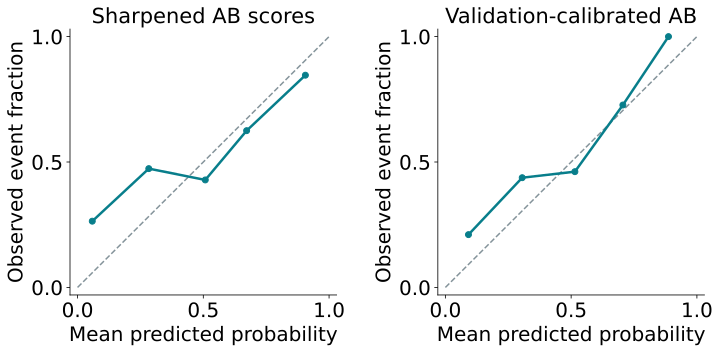

In [1]:
from demo import run
from IPython.display import SVG, display
report = run()
print({m:report['models'][m]['temperature'] for m in ('A','AB')})
print(report['test_metrics']['AB']['before']['Brier'], report['test_metrics']['AB']['after']['Brier'])
display(SVG(filename='calibration.svg'))

Interpret the reliability plot together with bin counts. Compare A and AB on the same group population, including groups with missing B.

[{'bin': [0.0, 0.2], 'count': 38, 'mean_probability': 0.09178676339160315, 'event_fraction': 0.21052631578947367}, {'bin': [0.2, 0.4], 'count': 32, 'mean_probability': 0.3054342705692135, 'event_fraction': 0.4375}, {'bin': [0.4, 0.6], 'count': 13, 'mean_probability': 0.5148847041115385, 'event_fraction': 0.46153846153846156}, {'bin': [0.6, 0.8], 'count': 11, 'mean_probability': 0.7056815123593719, 'event_fraction': 0.7272727272727273}, {'bin': [0.8, 1.0], 'count': 6, 'mean_probability': 0.887011629713344, 'event_fraction': 1.0}]
[('A', 0.2351711234929404), ('AB', 0.20834317621324977)]


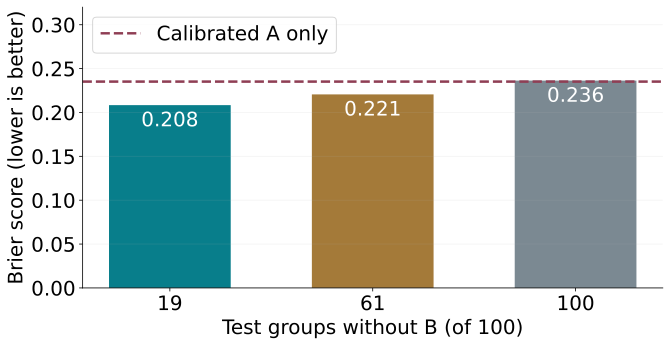

In [2]:
print(report['test_metrics']['AB']['after']['reliability_bins'])
print([(m, report['test_metrics'][m]['after']['Brier']) for m in ('A','AB')])
display(SVG(filename='missing-modality.svg'))

Modify a toy logit vector, not the frozen evaluation settings. Try several positive temperatures and verify ranking and threshold-0.5 invariance. Then explain why other probability thresholds need not be invariant.

In [3]:
import numpy as np
from demo import temperature_scale
logits = np.array([-2., -.5, .5, 2.])
for temperature in [0.5,1.,2.]:
    p = temperature_scale(logits, temperature)
    print(temperature, p, 'at 0.5:', p >= 0.5, 'at 0.7:', p >= 0.7)

0.5 [0.01798621 0.26894142 0.73105858 0.98201379] at 0.5: [False False  True  True] at 0.7: [False False  True  True]
1.0 [0.11920292 0.37754067 0.62245933 0.88079708] at 0.5: [False False  True  True] at 0.7: [False False False  True]
2.0 [0.26894142 0.4378235  0.5621765  0.73105858] at 0.5: [False False  True  True] at 0.7: [False False False  True]
